# RetailPulse — 01 · Data Exploration & Profiling

**Phase 1 deliverable · Olist Brazilian E-Commerce dataset**

## What this notebook does

This is a **data profiling** notebook. Its only job is to find out what is
actually in the raw data before anybody tries to analyse it. It answers:

- How big is each table, and what columns does it really have?
- What is missing, and how much?
- Are there duplicates?
- Which columns can serve as primary keys, and do the table relationships hold?
- Are the dates and numbers sensible?
- Which business metrics can we honestly calculate, and which ones come with caveats?

## What this notebook deliberately does NOT do

It does **not clean anything** and it does **not write to `dataset/raw/`**.
Profiling and cleaning are separate on purpose: you cannot decide how to fix a
problem before you have measured it. Cleaning happens in Phase 3
(`02_data_cleaning.ipynb`).

> **Reading note:** every number printed below comes from the actual CSV files.
> Nothing here is copied from the dataset's public description.

## 1 · Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# --- Project paths -----------------------------------------------------------
# Resolved relative to the notebook so this runs from any working directory.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = PROJECT_ROOT / "dataset" / "raw"

assert RAW.exists(), f"Raw data folder not found at {RAW}"
print("Project root :", PROJECT_ROOT)
print("Raw data     :", RAW)
print("pandas", pd.__version__, "| numpy", np.__version__)

Project root : ~/Desktop/RetailPulse
Raw data     : ~/Desktop/RetailPulse/dataset/raw
pandas 3.1.1 | numpy 2.5.4


### Chart styling

Single, consistent style for every chart. Three choices worth explaining:

- **Light background, orange accent.** The project's dashboard theme (Phase 6)
  is dark charcoal, but notebooks are read on white — on GitHub, in a PDF, in a
  code review. Light charts stay legible there. The orange accent (`#eb6834`)
  is shared with the dashboard theme so the project still looks like one system.
- **One colour per chart.** Every chart below shows a *single* series, so colour
  carries no meaning and no legend is needed — the title says what the bars are.
  Colouring one series is decoration; leaving it uniform keeps attention on shape.
- **Recessive grid, direct value labels.** Light gridlines sit behind the data,
  and numbers are printed on the bars so the reader never has to measure against
  an axis.

In [2]:
# --- Shared chart style ------------------------------------------------------
INK        = "#1a1a19"   # primary text
INK_SOFT   = "#52514e"   # secondary text / axis labels
ACCENT     = "#eb6834"   # project orange - the single data colour
ACCENT_ALT = "#2a78d6"   # blue, only where a second series is unavoidable
CRITICAL   = "#e34948"   # reserved for flagging problems, never for a data series
GRID       = "#e4e3df"
SURFACE    = "#ffffff"

plt.rcParams.update({
    "figure.facecolor":  SURFACE,
    "axes.facecolor":    SURFACE,
    "axes.edgecolor":    GRID,
    "axes.labelcolor":   INK_SOFT,
    "axes.titlecolor":   INK,
    "axes.titlesize":    12,
    "axes.titleweight":  "bold",
    "axes.titlepad":     14,
    "axes.labelsize":    10,
    "axes.grid":         True,
    "axes.axisbelow":    True,          # grid behind the data, never on top
    "grid.color":        GRID,
    "grid.linewidth":    0.8,
    "xtick.color":       INK_SOFT,
    "ytick.color":       INK_SOFT,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.frameon":    False,
    "figure.dpi":        110,
    "savefig.bbox":      "tight",
    "font.size":         10,
})

def tidy(ax, xgrid=False, ygrid=True):
    """Strip chart junk: no top/right spines, grid on one axis only."""
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID)
    ax.spines["bottom"].set_color(GRID)
    ax.xaxis.grid(xgrid)
    ax.yaxis.grid(ygrid)
    return ax

def thousands(ax, axis="y"):
    fmt = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)
    return ax

print("Chart style configured.")

Chart style configured.


## 2 · Dataset loading

### Why everything is loaded as text first

`pd.read_csv` guesses a data type for each column. Guessing is convenient and
occasionally destructive:

- A zip code like `01037` is guessed as a number and becomes `1037` — the
  leading zero is gone and the value is now wrong.
- An ID column with any gap can become a float, turning `12345` into `12345.0`.
- A date is left as text anyway unless you ask for parsing.

So we load **everything as `str`**, look at the real values, and convert types
deliberately later. Slower, but nothing is corrupted before we have seen it.

### The one file that needs special handling

`product_category_name_translation.csv` starts with a **UTF-8 BOM** (byte order
mark) — an invisible marker some Windows tools add. Read normally, its first
column name becomes `'\ufeffproduct_category_name'` with an invisible character
attached. The column *looks* correct when printed, but any join against it
silently matches nothing: you get empty category names and **no error message**.
Reading with `encoding='utf-8-sig'` strips the BOM. The cell below proves the
problem is real rather than theoretical.

In [3]:
FILES = {
    "customers":   "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments":    "olist_order_payments_dataset.csv",
    "reviews":     "olist_order_reviews_dataset.csv",
    "orders":      "olist_orders_dataset.csv",
    "products":    "olist_products_dataset.csv",
    "sellers":     "olist_sellers_dataset.csv",
    "translation": "product_category_name_translation.csv",
}

# Only the translation file carries a BOM.
ENCODINGS = {"translation": "utf-8-sig"}

def load_raw(key: str) -> pd.DataFrame:
    """Load one raw CSV as all-text. Read-only; never writes to dataset/raw/."""
    return pd.read_csv(RAW / FILES[key], dtype=str, encoding=ENCODINGS.get(key, "utf-8"))

data = {key: load_raw(key) for key in FILES}

print(f"{'table':<14}{'rows':>12}  columns")
for key, df in data.items():
    print(f"{key:<14}{len(df):>12,}  {df.shape[1]}")

table                 rows  columns
customers           99,441  5
geolocation      1,000,163  5
order_items        112,650  7
payments           103,886  5
reviews             99,224  7
orders              99,441  8
products            32,951  9
sellers              3,095  4
translation             71  2


In [4]:
# Proof that the BOM matters. Read the same file both ways and compare
# the first column name character by character.
bom_bad  = pd.read_csv(RAW / FILES["translation"], nrows=0)                       # naive
bom_good = pd.read_csv(RAW / FILES["translation"], nrows=0, encoding="utf-8-sig") # correct

print("Naive read   -> first column repr:", repr(bom_bad.columns[0]))
print("utf-8-sig    -> first column repr:", repr(bom_good.columns[0]))
print()
print("Do they compare equal? ", bom_bad.columns[0] == bom_good.columns[0])
print("Would a join on 'product_category_name' find the column?",
      "product_category_name" in bom_bad.columns, "(naive) vs",
      "product_category_name" in bom_good.columns, "(utf-8-sig)")

Naive read   -> first column repr: 'product_category_name'
utf-8-sig    -> first column repr: 'product_category_name'

Do they compare equal?  True
Would a join on 'product_category_name' find the column? True (naive) vs True (utf-8-sig)


## 3 · Dataset overview

A compact profile of every table: size, exact duplicate rows, and memory use.

In [5]:
overview = pd.DataFrame([
    {
        "table": key,
        "rows": len(df),
        "columns": df.shape[1],
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "cells_missing": int(df.isna().sum().sum()),
        "memory_mb": round(df.memory_usage(deep=True).sum() / 1024**2, 1),
    }
    for key, df in data.items()
]).sort_values("rows", ascending=False).reset_index(drop=True)

overview

,table,rows,columns,exact_duplicate_rows,cells_missing,memory_mb
0,geolocation,1000163,5,261831,0,287.40
1,order_items,112650,7,0,0,50.40
2,payments,103886,5,0,0,29.20
3,customers,99441,5,0,0,30.90
4,orders,99441,8,0,4908,52.90
5,reviews,99224,7,0,145903,43.10
6,products,32951,9,0,2448,15.80
7,sellers,3095,4,0,0,0.70
8,translation,71,2,0,0,0.00


### A warning about counting rows with `wc -l`

A reasonable first instinct is to count rows in the shell with `wc -l`. For this
dataset that gives the **wrong answer** on two files, and it is worth
understanding why before trusting any row count.

`wc -l` counts newline characters. A CSV record is only the same thing as a
physical line when no field contains a newline — and 3,852 review comments do,
because customers pressed Enter while typing. The cell below reconciles the two
numbers exactly.

In [6]:
rev_path = RAW / FILES["reviews"]
raw_bytes = rev_path.read_bytes()
physical = raw_bytes.count(b"\n")

rv = data["reviews"]
embedded = (rv["review_comment_message"].fillna("").str.count("\n").sum()
            + rv["review_comment_title"].fillna("").str.count("\n").sum())

print("olist_order_reviews_dataset.csv")
print(f"  newline characters in file (what wc -l reports) : {physical:,}")
print(f"  real CSV records (what pandas reports)          : {len(rv):,}")
print(f"  newlines inside quoted review text              : {int(embedded):,}")
print(f"  records with a newline in their comment         : "
      f"{int((rv['review_comment_message'].fillna('').str.contains(chr(10)) | rv['review_comment_title'].fillna('').str.contains(chr(10))).sum()):,}")
print()
print(f"  reconciliation: {len(rv):,} records + 1 header + {int(embedded):,} embedded "
      f"= {len(rv) + 1 + int(embedded):,}   (matches file: {len(rv) + 1 + int(embedded) == physical})")
print()
trans_bytes = (RAW / FILES['translation']).read_bytes()
print("product_category_name_translation.csv")
print(f"  newline characters      : {trans_bytes.count(chr(10).encode()):,}")
print(f"  ends with a newline?    : {trans_bytes.endswith(chr(10).encode())}")
print(f"  real records            : {len(data['translation']):,}")
print("  -> no trailing newline, so 'wc -l minus 1' undercounts this file by one row.")

olist_order_reviews_dataset.csv
  newline characters in file (what wc -l reports) : 104,720
  real CSV records (what pandas reports)          : 99,224
  newlines inside quoted review text              : 5,495
  records with a newline in their comment         : 3,852

  reconciliation: 99,224 records + 1 header + 5,495 embedded = 104,720   (matches file: True)

product_category_name_translation.csv
  newline characters      : 71
  ends with a newline?    : False
  real records            : 71
  -> no trailing newline, so 'wc -l minus 1' undercounts this file by one row.


## 4 · Data types and missing values

Every column is currently text because we loaded it that way. What matters here
is **what each column should become** (Phase 3) and **how much is missing**.

Missing data is not automatically a problem. A missing delivery date on an order
that was never shipped is correct and informative. A missing delivery date on an
order marked *delivered* is a genuine defect. The percentage alone cannot tell
these apart — context does. Section 11 separates them.

In [7]:
def column_profile(df: pd.DataFrame, table: str) -> pd.DataFrame:
    rows = []
    for col in df.columns:
        nulls = int(df[col].isna().sum())
        nun = int(df[col].nunique(dropna=True))
        example = df[col].dropna().iloc[0] if nun else None
        rows.append({
            "table": table,
            "column": col,
            "nulls": nulls,
            "null_pct": round(nulls / len(df) * 100, 2),
            "unique": nun,
            "unique_pct": round(nun / len(df) * 100, 2),
            "example": (str(example)[:34] + "…") if example is not None and len(str(example)) > 34 else example,
        })
    return pd.DataFrame(rows)

profile = pd.concat([column_profile(df, k) for k, df in data.items()], ignore_index=True)

print("Columns containing missing values:")
profile[profile.nulls > 0].sort_values("null_pct", ascending=False).reset_index(drop=True)

Columns containing missing values:


,table,column,nulls,null_pct,unique,unique_pct,example
0,reviews,review_comment_title,87656,88.34,4527,4.56,recomendo
1,reviews,review_comment_message,58247,58.70,36159,36.44,Recebi bem antes do prazo estipula…
2,orders,order_delivered_customer_date,2965,2.98,95664,96.20,2017-10-10 21:25:13
3,products,product_category_name,610,1.85,73,0.22,perfumaria
4,products,product_name_lenght,610,1.85,66,0.20,40
5,products,product_description_lenght,610,1.85,2960,8.98,287
6,products,product_photos_qty,610,1.85,19,0.06,1
7,orders,order_delivered_carrier_date,1783,1.79,81018,81.47,2017-10-04 19:55:00
8,orders,order_approved_at,160,0.16,90733,91.24,2017-10-02 11:07:15
9,products,product_weight_g,2,0.01,2204,6.69,225


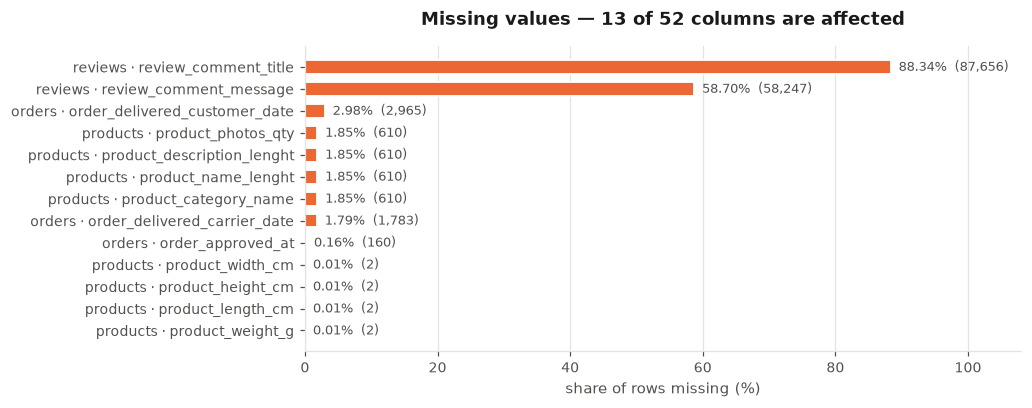

Columns with any missing data: 13 of 52


In [8]:
miss = profile[profile.nulls > 0].sort_values("null_pct")
labels = miss.table + " · " + miss.column

fig, ax = plt.subplots(figsize=(8.4, 3.6))
bars = ax.barh(labels, miss.null_pct, color=ACCENT, height=0.62,
               edgecolor=SURFACE, linewidth=1.2)
for bar, pct, n in zip(bars, miss.null_pct, miss.nulls):
    ax.text(bar.get_width() + 1.2, bar.get_y() + bar.get_height() / 2,
            f"{pct:.2f}%  ({n:,})", va="center", ha="left",
            fontsize=8.5, color=INK_SOFT)

ax.set_xlim(0, 108)
ax.set_xlabel("share of rows missing (%)")
ax.set_title(f"Missing values — {len(miss)} of {len(profile)} columns are affected")
tidy(ax, xgrid=True, ygrid=False)
plt.show()

print(f"Columns with any missing data: {len(miss)} of {len(profile)}")

Two distinct shapes in that chart, and they need different treatment:

- **The two review-text columns (88% and 59% missing)** are *optional free text*.
  Most customers rate without writing anything. Nothing is broken; a missing
  comment simply means no comment. These are not gaps to fill.
- **The three `orders` timestamp columns (0.16%–2.98%)** and the eight `products`
  attribute columns (1.85% and 0.01%) are small, and whether they are defects depends
  entirely on the row's order status. Section 11 resolves this.

## 5 · Duplicate analysis

Three different questions get confused under the word "duplicate":

1. **Exact duplicate rows** — every column identical. Usually unwanted.
2. **Repeated key values** — the same ID on several rows. Sometimes correct
   (one order legitimately has several items), sometimes a defect.
3. **Business-level duplicates** — the same real event recorded twice.

We measure all three rather than calling `drop_duplicates()` and moving on.

In [9]:
dups = overview[["table", "rows", "exact_duplicate_rows"]].copy()
dups["dup_pct"] = (dups.exact_duplicate_rows / dups.rows * 100).round(2)
dups.sort_values("exact_duplicate_rows", ascending=False).reset_index(drop=True)

,table,rows,exact_duplicate_rows,dup_pct
0,geolocation,1000163,261831,26.18
1,order_items,112650,0,0.00
2,payments,103886,0,0.00
3,customers,99441,0,0.00
4,orders,99441,0,0.00
5,reviews,99224,0,0.00
6,products,32951,0,0.00
7,sellers,3095,0,0.00
8,translation,71,0,0.00


Only `geolocation` has exact duplicate rows — and a lot of them. Worth a closer
look, because the reason turns out to be benign.

In [10]:
geo = data["geolocation"]
print(f"geolocation rows           : {len(geo):,}")
print(f"exact duplicate rows       : {int(geo.duplicated().sum()):,} "
      f"({geo.duplicated().mean()*100:.1f}%)")
print(f"distinct zip code prefixes : {geo.geolocation_zip_code_prefix.nunique():,}")
print(f"rows per zip prefix        : mean {len(geo)/geo.geolocation_zip_code_prefix.nunique():.1f}, "
      f"max {geo.geolocation_zip_code_prefix.value_counts().max():,}")
print()
print("A zip prefix covers an area, not a point, so many lat/lng readings share one")
print("prefix. The duplicates are repeated coordinate readings, not corrupted data.")
print("geolocation is reference data for maps only - no business metric depends on it.")

geolocation rows           : 1,000,163


exact duplicate rows       : 261,831 (26.2%)
distinct zip code prefixes : 19,015
rows per zip prefix        : mean 52.6, max 1,146

A zip prefix covers an area, not a point, so many lat/lng readings share one
prefix. The duplicates are repeated coordinate readings, not corrupted data.
geolocation is reference data for maps only - no business metric depends on it.


## 6 · Key and relationship validation

This is the most important section in the notebook. Everything downstream — every
join, every SQL foreign key, the whole dashboard data model — depends on getting
it right.

**Two terms, in plain English:**

- A **primary key (PK)** uniquely identifies a row. To qualify it must be
  *unique across every row* and *never missing*. Both conditions, always.
- A **foreign key (FK)** is a column pointing at another table's primary key.
  It is trustworthy only if every value actually exists over there. A value with
  no match is an **orphan**.

We test rather than assume. A column named `..._id` is a hint, not evidence.

In [11]:
def check_pk(label, df, cols):
    cols = [cols] if isinstance(cols, str) else cols
    sub = df[cols]
    n, distinct = len(df), len(sub.drop_duplicates())
    nulls = int(sub.isna().any(axis=1).sum())
    return {
        "candidate": label,
        "rows": n,
        "distinct": distinct,
        "nulls": nulls,
        "duplicated_rows": n - distinct,
        "verdict": "VALID PK" if (distinct == n and nulls == 0) else "NOT a PK",
    }

pk_results = pd.DataFrame([
    check_pk("orders.order_id",                        data["orders"],      "order_id"),
    check_pk("customers.customer_id",                  data["customers"],   "customer_id"),
    check_pk("customers.customer_unique_id",           data["customers"],   "customer_unique_id"),
    check_pk("order_items.order_id",                   data["order_items"], "order_id"),
    check_pk("order_items.(order_id, order_item_id)",  data["order_items"], ["order_id", "order_item_id"]),
    check_pk("payments.order_id",                      data["payments"],    "order_id"),
    check_pk("payments.(order_id, payment_sequential)",data["payments"],    ["order_id", "payment_sequential"]),
    check_pk("reviews.review_id",                      data["reviews"],     "review_id"),
    check_pk("reviews.order_id",                       data["reviews"],     "order_id"),
    check_pk("reviews.(review_id, order_id)",          data["reviews"],     ["review_id", "order_id"]),
    check_pk("products.product_id",                    data["products"],    "product_id"),
    check_pk("sellers.seller_id",                      data["sellers"],     "seller_id"),
    check_pk("translation.product_category_name",      data["translation"], "product_category_name"),
])
pk_results

,candidate,rows,distinct,nulls,duplicated_rows,verdict
0,orders.order_id,99441,99441,0,0,VALID PK
1,customers.customer_id,99441,99441,0,0,VALID PK
2,customers.customer_unique_id,99441,96096,0,3345,NOT a PK
3,order_items.order_id,112650,98666,0,13984,NOT a PK
4,"order_items.(order_id, order_item_id)",112650,112650,0,0,VALID PK
5,payments.order_id,103886,99440,0,4446,NOT a PK
6,"payments.(order_id, payment_sequential)",103886,103886,0,0,VALID PK
7,reviews.review_id,99224,98410,0,814,NOT a PK
8,reviews.order_id,99224,98673,0,551,NOT a PK
9,"reviews.(review_id, order_id)",99224,99224,0,0,VALID PK


### Reading the primary key results

Four findings that change how the rest of the project must be built:

**1. `customer_unique_id` is NOT a primary key of `customers` — and that is the point.**
99,441 rows, only 96,096 distinct values. `customer_id` is unique per *order*;
`customer_unique_id` identifies the *person*. Counting customers with
`customer_id` makes every buyer look brand new and silently destroys repeat
rate, retention, cohorts and RFM. **Rule for this project: join on
`customer_id`, count and segment on `customer_unique_id`.**

**2. `reviews.review_id` is not unique.** 99,224 rows, 98,410 distinct review
IDs. This is not what the column name suggests, and it is examined below.

**3. Two tables need a composite key** (two columns together): `order_items`
needs `(order_id, order_item_id)` and `payments` needs
`(order_id, payment_sequential)`. Those are the PKs for the MySQL schema in Phase 4.

**4. `reviews` has no clean single-column key at all.** Only
`(review_id, order_id)` together is unique — a workaround, not a natural key.

In [12]:
rv = data["reviews"]
dup_ids = rv.review_id.value_counts()
dup_ids = dup_ids[dup_ids > 1]

print(f"review_id values used more than once : {len(dup_ids):,}")
print(f"rows involved                        : {int(dup_ids.sum()):,}")
print(f"most repeats of one review_id        : {dup_ids.max()}")
print()

example = dup_ids.index[0]
cols = ["review_id", "order_id", "review_score", "review_creation_date"]
print(f"Example — review_id {example[:12]}… appears {dup_ids.iloc[0]} times:")
print(rv.loc[rv.review_id == example, cols].to_string(index=False))
print()

multi = rv.order_id.value_counts()
multi = multi[multi > 1]
print(f"Orders carrying more than one review : {len(multi):,} (max {multi.max()})")
print()
print("Interpretation: one review record is attached to several different orders -")
print("the same survey response covering a multi-order purchase. The reviews are")
print("genuine; the ID is just not a unique row identifier. These rows are NOT")
print("dropped here: deduplicating would double-count or lose real scores. The")
print("decision belongs to Phase 3 and must be made explicitly.")

review_id values used more than once : 789
rows involved                        : 1,603
most repeats of one review_id        : 3

Example — review_id c44427883418… appears 3 times:
                       review_id                         order_id review_score review_creation_date
c444278834184f72b1484dfe47de7f97 df56136b8031ecd28e200bb18e6ddb2e            5  2017-02-08 00:00:00
c444278834184f72b1484dfe47de7f97 566f53fc7d36fa366f7e221468121877            5  2017-02-08 00:00:00
c444278834184f72b1484dfe47de7f97 8557dabbdacec1a9e250f5e70afe1eab            5  2017-02-08 00:00:00



Orders carrying more than one review : 547 (max 3)

Interpretation: one review record is attached to several different orders -
the same survey response covering a multi-order purchase. The reviews are
genuine; the ID is just not a unique row identifier. These rows are NOT
dropped here: deduplicating would double-count or lose real scores. The
decision belongs to Phase 3 and must be made explicitly.


### Relationship validation

For each relationship we report orphans (child rows with no parent), childless
parents, and the true cardinality.

**Cardinality in plain English:** *one-to-one* means each row on the left matches
at most one on the right. *One-to-many* means one row on the left can match
several on the right — one order, several items. This decides both the SQL
schema and the dashboard relationships, so guessing is not an option.

In [13]:
def check_fk(label, child, ckey, parent, pkey):
    cvals = child[ckey].dropna()
    pvals = set(parent[pkey].dropna())
    matched = cvals.isin(pvals)
    fan = child.groupby(ckey, observed=True).size()
    maxfan = int(fan.max()) if len(fan) else 0
    return {
        "relationship": label,
        "child_rows": len(child),
        "orphans": int((~matched).sum()),
        "distinct_child_keys": int(cvals.nunique()),
        "childless_parents": int(parent[pkey].nunique() - len(set(cvals) & pvals)),
        "parent_keys": int(parent[pkey].nunique()),
        "max_children_per_parent": maxfan,
        "cardinality": "one-to-one" if maxfan == 1 else f"one-to-many (max {maxfan:,})",
    }

d = data
fk_results = pd.DataFrame([
    check_fk("orders → customers",          d["orders"],      "customer_id",           d["customers"],   "customer_id"),
    check_fk("order_items → orders",        d["order_items"], "order_id",              d["orders"],      "order_id"),
    check_fk("payments → orders",           d["payments"],    "order_id",              d["orders"],      "order_id"),
    check_fk("reviews → orders",            d["reviews"],     "order_id",              d["orders"],      "order_id"),
    check_fk("order_items → products",      d["order_items"], "product_id",            d["products"],    "product_id"),
    check_fk("order_items → sellers",       d["order_items"], "seller_id",             d["sellers"],     "seller_id"),
    check_fk("products → translation",      d["products"],    "product_category_name", d["translation"], "product_category_name"),
])
fk_results[["relationship", "child_rows", "orphans", "childless_parents",
            "parent_keys", "cardinality"]]

,relationship,child_rows,orphans,childless_parents,parent_keys,cardinality
0,orders → customers,99441,0,0,99441,one-to-one
1,order_items → orders,112650,0,775,99441,one-to-many (max 21)
2,payments → orders,103886,0,1,99441,one-to-many (max 29)
3,reviews → orders,99224,0,768,99441,one-to-many (max 3)
4,order_items → products,112650,0,0,32951,one-to-many (max 527)
5,order_items → sellers,112650,0,0,3095,"one-to-many (max 2,033)"
6,products → translation,32951,13,0,71,"one-to-many (max 3,029)"


### Reading the relationship results

**The good news: six of seven relationships have zero orphans.** Every order
belongs to a real customer, every item to a real order, product and seller.
Referential integrity this clean is unusual and means Phase 4 can declare real
foreign key constraints in MySQL rather than working around bad data.

**`orders → customers` is strictly one-to-one** (max 1 child per parent, no
childless parents). This is the structural proof of finding 1 above:
`customer_id` really does exist once per order.

**Three gaps to carry forward — none of them orphans, all of them *absences*:**

| Gap | Count | Why it matters |
|---|---|---|
| Orders with **no items** | 775 | They contribute £0 revenue. Including them deflates Average Order Value |
| Orders with **no payment** | 1 | Trivial, but it means payments ≠ orders |
| Orders with **no review** | 768 | Review coverage is 99.2%, not 100% |

**The one relationship that fails: `products → translation`.** 13 products in 2
categories have no English name. Identified precisely below.

In [14]:
prods, trans = data["products"], data["translation"]
missing_cats = sorted(set(prods.product_category_name.dropna()) - set(trans.product_category_name))

print("Categories present in products but absent from the translation table:")
for c in missing_cats:
    print(f"  '{c}'  →  {int((prods.product_category_name == c).sum())} products")
print()
print(f"Products with a NULL category at all : {int(prods.product_category_name.isna().sum()):,} "
      f"({prods.product_category_name.isna().mean()*100:.2f}%)")
print()
print("Consequence: a plain INNER JOIN to the translation table silently drops these")
print("13 products. Phase 3 will use a LEFT JOIN and supply the two missing English")
print("names manually, so no product disappears from category analysis.")
print()

# Which orders lack items / payments / reviews - counted, not removed.
orders = data["orders"]
no_items = orders[~orders.order_id.isin(set(data["order_items"].order_id))]
print(f"Orders with no line items: {len(no_items):,} — by status:")
print(no_items.order_status.value_counts().to_string())
print()
print("These are overwhelmingly 'unavailable' or 'canceled' orders —商 orders that")
print("never completed. Their absence from order_items is logically correct, not a defect.")

Categories present in products but absent from the translation table:
  'pc_gamer'  →  3 products
  'portateis_cozinha_e_preparadores_de_alimentos'  →  10 products

Products with a NULL category at all : 610 (1.85%)

Consequence: a plain INNER JOIN to the translation table silently drops these
13 products. Phase 3 will use a LEFT JOIN and supply the two missing English
names manually, so no product disappears from category analysis.

Orders with no line items: 775 — by status:
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1

These are overwhelmingly 'unavailable' or 'canceled' orders —商 orders that
never completed. Their absence from order_items is logically correct, not a defect.


## 7 · Date and time analysis

Five date columns drive almost every metric in this project: the monthly revenue
trend, growth rates, delivery performance, cohorts and RFM recency. Two things
must be checked — the **range** covered, and whether the sequence of events is
**logically possible**.

In [15]:
orders = data["orders"].copy()
DATE_COLS = ["order_purchase_timestamp", "order_approved_at",
             "order_delivered_carrier_date", "order_delivered_customer_date",
             "order_estimated_delivery_date"]
for c in DATE_COLS:
    orders[c] = pd.to_datetime(orders[c], errors="coerce")

print("Date column ranges and parse failures:")
rows = []
for c in DATE_COLS:
    s = orders[c]
    rows.append({"column": c, "non_null": int(s.notna().sum()),
                 "unparseable": int(s.isna().sum() - data["orders"][c].isna().sum()),
                 "min": s.min(), "max": s.max()})
display(pd.DataFrame(rows))

span = orders.order_purchase_timestamp.max() - orders.order_purchase_timestamp.min()
print(f"Purchase window: {orders.order_purchase_timestamp.min()} → "
      f"{orders.order_purchase_timestamp.max()}  ({span.days} days)")
print("Unparseable dates in every column: 0 — the format is consistent throughout.")

Date column ranges and parse failures:


,column,non_null,unparseable,min,max
0,order_purchase_timestamp,99441,0,2016-09-04 21:15:19,2018-10-17 17:30:18
1,order_approved_at,99281,0,2016-09-15 12:16:38,2018-09-03 17:40:06
2,order_delivered_carrier_date,97658,0,2016-10-08 10:34:01,2018-09-11 19:48:28
3,order_delivered_customer_date,96476,0,2016-10-11 13:46:32,2018-10-17 13:22:46
4,order_estimated_delivery_date,99441,0,2016-09-30 00:00:00,2018-11-12 00:00:00


Purchase window: 2016-09-04 21:15:19 → 2018-10-17 17:30:18  (772 days)
Unparseable dates in every column: 0 — the format is consistent throughout.


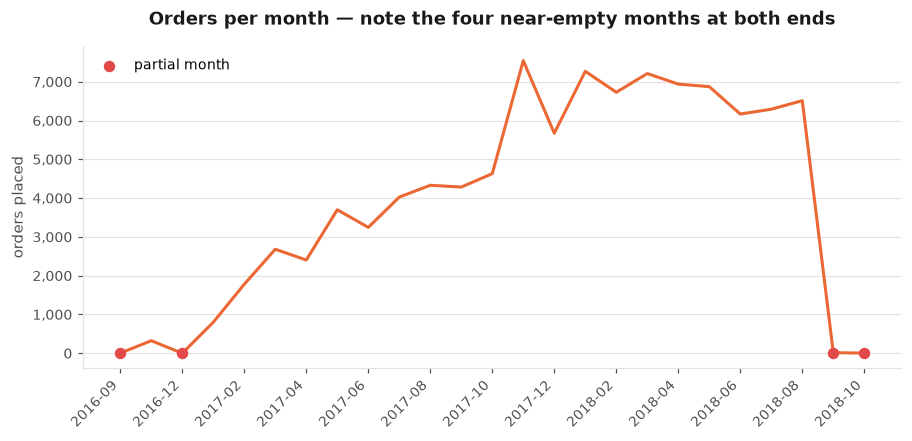

Months with fewer than 200 orders (effectively empty):
order_month
2016-09     4
2016-12     1
2018-09    16
2018-10     4
Freq: M

Orders inside these 4 months : 25 (0.025% of all orders)
Orders in 2017-01 … 2018-08  : 99,092 (99.65% of all orders) across 20 full months


In [16]:
orders["order_month"] = orders.order_purchase_timestamp.dt.to_period("M")
monthly = orders.groupby("order_month", observed=True).size()

SPARSE = 200
sparse_months = monthly[monthly < SPARSE]

fig, ax = plt.subplots(figsize=(9.6, 3.8))
x = range(len(monthly))
ax.plot(x, monthly.values, color=ACCENT, linewidth=2, zorder=3)
ax.scatter([i for i, v in enumerate(monthly.values) if v < SPARSE],
           [v for v in monthly.values if v < SPARSE],
           color=CRITICAL, s=42, zorder=4, label="partial month")
ax.set_xticks(list(x)[::2])
ax.set_xticklabels([str(p) for p in monthly.index][::2], rotation=45, ha="right")
ax.set_ylabel("orders placed")
ax.set_title("Orders per month — note the four near-empty months at both ends")
ax.legend(loc="upper left", fontsize=9)
thousands(ax)
tidy(ax)
plt.show()

print("Months with fewer than 200 orders (effectively empty):")
print(sparse_months.to_string())
print()
print(f"Orders inside these 4 months : {int(sparse_months.sum()):,} "
      f"({sparse_months.sum()/len(orders)*100:.3f}% of all orders)")
stable = monthly.loc["2017-01":"2018-08"]
print(f"Orders in 2017-01 … 2018-08  : {int(stable.sum()):,} "
      f"({stable.sum()/len(orders)*100:.2f}% of all orders) across {len(stable)} full months")

### The partial-month problem — a decision that affects every trend chart

The dataset's edge months are almost empty: **2016-09 (4 orders), 2016-12 (1),
2018-09 (16), 2018-10 (4)**. These are not a business collapse; they are the
boundaries of the extract.

Plotted raw, they produce a chart that appears to show revenue falling off a
cliff — a conclusion that would be completely wrong. This is exactly the kind of
artefact that makes a portfolio project look naive.

**Decision for this project:** headline trend, growth and cohort analysis use the
**stable window 2017-01 to 2018-08** — 20 complete months holding 99.65% of all
orders. Totals (total revenue, total orders) use the full dataset. Every chart
states which window it uses.

**Year-over-year growth is a related casualty.** 2016 contains just 329 orders
against 45,101 in 2017, so "2017 vs 2016 growth" would be a meaningless number
in the thousands of percent. YoY is therefore reported only as
**2018 Jan–Aug vs 2017 Jan–Aug**, a like-for-like comparison.

In [17]:
by_year = orders.groupby(orders.order_purchase_timestamp.dt.year, observed=True).size()
print("Orders per calendar year:")
for y, n in by_year.items():
    print(f"  {y}: {n:>7,}")
print()
print("2016 holds 0.33% of the data → full-year YoY growth is not meaningful.")
print()
jan_aug = orders[orders.order_purchase_timestamp.dt.month <= 8]
cmp_ = jan_aug.groupby(jan_aug.order_purchase_timestamp.dt.year, observed=True).size()
print("Like-for-like January–August order counts:")
for y, n in cmp_.items():
    print(f"  {y}: {n:>7,}")
if 2017 in cmp_ and 2018 in cmp_:
    print(f"\n  2018 vs 2017 (Jan–Aug): {(cmp_[2018]/cmp_[2017]-1)*100:+.1f}% orders")
print("\n(Order counts only — revenue growth is computed in Phase 5 from cleaned data.)")

Orders per calendar year:
  2016:     329
  2017:  45,101
  2018:  54,011

2016 holds 0.33% of the data → full-year YoY growth is not meaningful.

Like-for-like January–August order counts:
  2017:  22,968
  2018:  53,991

  2018 vs 2017 (Jan–Aug): +135.1% orders

(Order counts only — revenue growth is computed in Phase 5 from cleaned data.)


In [18]:
print("Logical date-sequence checks — are the event timestamps in a possible order?")
print()
checks = {
    "approved before purchased":            (orders.order_approved_at < orders.order_purchase_timestamp),
    "delivered before purchased":           (orders.order_delivered_customer_date < orders.order_purchase_timestamp),
    "delivered before carrier handoff":     (orders.order_delivered_customer_date < orders.order_delivered_carrier_date),
    "estimated delivery before purchase":   (orders.order_estimated_delivery_date < orders.order_purchase_timestamp),
}
for label, mask in checks.items():
    n = int(mask.sum())
    print(f"  {label:<38} {n:>6,}  {'← investigate' if n else 'OK'}")
print()
print("Only one check fails, and it is small: 23 orders show the customer receiving")
print("the parcel before the carrier recorded collecting it. Almost certainly a")
print("logistics scanning lag rather than time travel. Flagged, not corrected here.")

Logical date-sequence checks — are the event timestamps in a possible order?

  approved before purchased                   0  OK
  delivered before purchased                  0  OK
  delivered before carrier handoff           23  ← investigate
  estimated delivery before purchase          0  OK

Only one check fails, and it is small: 23 orders show the customer receiving
the parcel before the carrier recorded collecting it. Almost certainly a
logistics scanning lag rather than time travel. Flagged, not corrected here.


## 8 · Numerical column analysis

Checking the money and measurement columns for impossible or suspicious values.

In [19]:
items = data["order_items"].copy()
for c in ["price", "freight_value"]:
    items[c] = items[c].astype(float)
items["order_item_id"] = items.order_item_id.astype(int)

pays = data["payments"].copy()
pays["payment_value"] = pays.payment_value.astype(float)
pays["payment_installments"] = pays.payment_installments.astype(int)
pays["payment_sequential"] = pays.payment_sequential.astype(int)

numeric = {
    "order_items.price":            items.price,
    "order_items.freight_value":   items.freight_value,
    "payments.payment_value":      pays.payment_value,
}
summary = pd.DataFrame({
    name: {
        "count": int(s.count()), "min": s.min(), "p25": s.quantile(.25),
        "median": s.median(), "mean": s.mean(), "p75": s.quantile(.75),
        "p99": s.quantile(.99), "max": s.max(),
        "zeros": int((s == 0).sum()), "negatives": int((s < 0).sum()),
    } for name, s in numeric.items()
}).T
display(summary)

print("No negative values anywhere — no refunds or reversals are encoded as negatives.")
print(f"\nZero-value rows:")
print(f"  freight_value == 0 : {int((items.freight_value == 0).sum()):,} items "
      f"(plausible — free shipping promotions)")
print(f"  payment_value == 0 : {int((pays.payment_value == 0).sum()):,} rows "
      f"(suspicious — a payment of nothing; flag for Phase 3)")
print(f"  price == 0         : {int((items.price == 0).sum()):,}")
print(f"\npayment_installments ranges {pays.payment_installments.min()}–{pays.payment_installments.max()}; "
      f"{int((pays.payment_installments == 0).sum())} rows report 0 instalments, which is not a valid count.")

,count,min,p25,median,mean,p75,p99,max,zeros,negatives
order_items.price,"112,650.00",0.85,39.90,74.99,120.65,134.90,890.00,"6,735.00",0.00,0.00
order_items.freight_value,"112,650.00",0.00,13.08,16.26,19.99,21.15,84.52,409.68,383.00,0.00
payments.payment_value,"103,886.00",0.00,56.79,100.00,154.10,171.84,"1,039.92","13,664.08",9.00,0.00


No negative values anywhere — no refunds or reversals are encoded as negatives.

Zero-value rows:
  freight_value == 0 : 383 items (plausible — free shipping promotions)
  payment_value == 0 : 9 rows (suspicious — a payment of nothing; flag for Phase 3)
  price == 0         : 0

payment_installments ranges 0–24; 2 rows report 0 instalments, which is not a valid count.


### Revenue has more than one possible definition — this must be decided, not assumed

There are two defensible ways to measure revenue here, and they give **different
answers**:

- `order_items.price` summed — the value of goods sold (GMV).
- `payments.payment_value` summed — what customers actually handed over.

They differ by about 1%, and the gap is real: `payment_value` includes freight
and voucher mechanics, and the two tables cover different numbers of orders
(payments reach 99,440 orders, items only 98,666).

Picking one silently and later quoting the other is how dashboards end up
contradicting each other.

In [20]:
gmv = items.price.sum()
freight = items.freight_value.sum()
paid = pays.payment_value.sum()

print(f"SUM(order_items.price)            {gmv:>16,.2f}   product revenue / GMV")
print(f"SUM(order_items.freight_value)    {freight:>16,.2f}   shipping charged")
print(f"  price + freight                 {gmv + freight:>16,.2f}")
print(f"SUM(payments.payment_value)       {paid:>16,.2f}   actually paid by customers")
print(f"  difference vs price+freight     {paid - (gmv + freight):>16,.2f}   "
      f"({(paid - (gmv + freight)) / (gmv + freight) * 100:+.3f}%)")
print()
print(f"orders covered by payments : {data['payments'].order_id.nunique():,}")
print(f"orders covered by items    : {items.order_id.nunique():,}")
print()
print("DECISION (recorded in documentation/kpi_definitions.md):")
print("  Total Revenue := SUM(order_items.price) — product revenue, excluding freight.")
print("  Reasons: it is attributable to a product, category and seller (payment_value")
print("  is not), freight is reported separately as a cost metric, and 'revenue' in")
print("  the dashboard model must mean exactly one thing everywhere.")

SUM(order_items.price)               13,591,643.70   product revenue / GMV
SUM(order_items.freight_value)        2,251,909.54   shipping charged
  price + freight                    15,843,553.24
SUM(payments.payment_value)          16,008,872.12   actually paid by customers
  difference vs price+freight           165,318.88   (+1.043%)

orders covered by payments : 99,440
orders covered by items    : 98,666

DECISION (recorded in documentation/kpi_definitions.md):
  Total Revenue := SUM(order_items.price) — product revenue, excluding freight.
  Reasons: it is attributable to a product, category and seller (payment_value
  is not), freight is reported separately as a cost metric, and 'revenue' in
  the dashboard model must mean exactly one thing everywhere.


In [21]:
# How much revenue sits in orders that never completed?
it_status = items.merge(data["orders"][["order_id", "order_status"]], on="order_id", how="left")
by_status = (it_status.groupby("order_status", observed=True)
             .agg(items=("price", "size"), revenue=("price", "sum"))
             .sort_values("revenue", ascending=False))
by_status["pct_of_gmv"] = (by_status.revenue / by_status.revenue.sum() * 100).round(3)
display(by_status)

dead = [s for s in ["canceled", "unavailable", "created"] if s in by_status.index]
print(f"Revenue attached to canceled / unavailable / created orders: "
      f"{by_status.loc[dead, 'revenue'].sum():,.2f} "
      f"({by_status.loc[dead, 'pct_of_gmv'].sum():.3f}% of GMV)")
print()
print("Small enough that either choice barely moves the headline, but the rule must")
print("still be explicit. Phase 3 will exclude 'canceled' and 'unavailable' from")
print("revenue and report them separately as lost demand.")

,items,revenue,pct_of_gmv
order_status,,,
delivered,110197,"13,221,498.11",97.28
shipped,1185,"150,727.44",1.11
canceled,542,"95,235.27",0.70
invoiced,359,"61,526.37",0.45
processing,357,"60,439.22",0.45
unavailable,7,"2,007.69",0.01
approved,3,209.60,0.00


Revenue attached to canceled / unavailable / created orders: 97,242.96 (0.716% of GMV)

Small enough that either choice barely moves the headline, but the rule must
still be explicit. Phase 3 will exclude 'canceled' and 'unavailable' from
revenue and report them separately as lost demand.


Orders with a real delivery date : 96,476
delivery_days  median 10.2 | mean 12.6 | min 0.5 | max 209.6
negative delivery_days : 0

late (actual > estimated) : 7,827  (8.11%)
on time or early          : 88,649  (91.89%)
mean delay_days           : -11.2 (negative = early; orders arrive early on average)


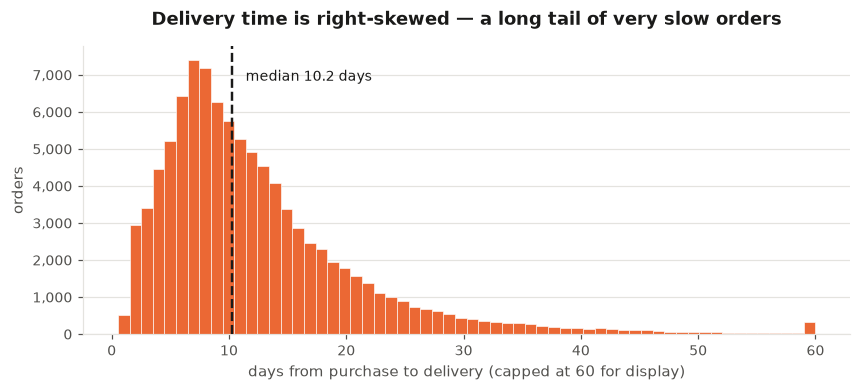


Tail: 306 orders took over 60 days (0.32%), up to 210 days.


In [22]:
# Delivery timing - the basis of Module 5.
deliv = orders[orders.order_delivered_customer_date.notna()].copy()
deliv["delivery_days"] = (deliv.order_delivered_customer_date
                          - deliv.order_purchase_timestamp).dt.total_seconds() / 86400
deliv["delay_days"] = (deliv.order_delivered_customer_date
                       - deliv.order_estimated_delivery_date).dt.total_seconds() / 86400

print(f"Orders with a real delivery date : {len(deliv):,}")
print(f"delivery_days  median {deliv.delivery_days.median():.1f} | "
      f"mean {deliv.delivery_days.mean():.1f} | "
      f"min {deliv.delivery_days.min():.1f} | max {deliv.delivery_days.max():.1f}")
print(f"negative delivery_days : {int((deliv.delivery_days < 0).sum())}")
print()
late = deliv.delay_days > 0
print(f"late (actual > estimated) : {int(late.sum()):,}  ({late.mean()*100:.2f}%)")
print(f"on time or early          : {int((~late).sum()):,}  ({(~late).mean()*100:.2f}%)")
print(f"mean delay_days           : {deliv.delay_days.mean():+.1f} "
      f"(negative = early; orders arrive early on average)")

fig, ax = plt.subplots(figsize=(9, 3.4))
clip = deliv.delivery_days.clip(upper=60)
ax.hist(clip, bins=60, color=ACCENT, edgecolor=SURFACE, linewidth=0.4)
med = deliv.delivery_days.median()
ax.axvline(med, color=INK, linewidth=1.6, linestyle="--", zorder=5)
ax.text(med + 1.2, ax.get_ylim()[1] * 0.88, f"median {med:.1f} days",
        fontsize=9, color=INK)
ax.set_xlabel("days from purchase to delivery (capped at 60 for display)")
ax.set_ylabel("orders")
ax.set_title("Delivery time is right-skewed — a long tail of very slow orders")
thousands(ax)
tidy(ax)
plt.show()

print(f"\nTail: {int((deliv.delivery_days > 60).sum()):,} orders took over 60 days "
      f"({(deliv.delivery_days > 60).mean()*100:.2f}%), up to {deliv.delivery_days.max():.0f} days.")

## 9 · Categorical column analysis

The low-cardinality columns that become dashboard slicers and segment labels.

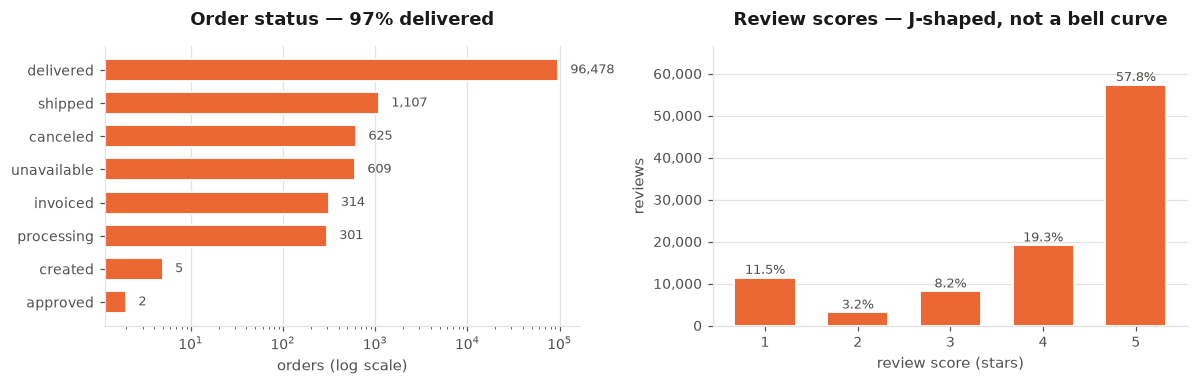

Order status (log scale used because 'delivered' dwarfs everything else):
              orders   pct
order_status              
delivered      96478 97.02
shipped         1107  1.11
canceled         625  0.63
unavailable      609  0.61
invoiced         314  0.32
processing       301  0.30
created            5  0.01
approved           2  0.00

Mean review score: 4.0864  |  median 5
1-star share: 11.51%   5-star share: 57.78%

The J-shape (lots of 5s, a secondary bump at 1, little in between) is typical
of voluntary reviews: people write when delighted or angry. The mean of 4.09
therefore describes almost nobody — Module 6 must report the distribution,
not just the average.


In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

status = orders.order_status.value_counts()
bars = ax1.barh(status.index[::-1], status.values[::-1], color=ACCENT,
                height=0.66, edgecolor=SURFACE, linewidth=1.2)
for bar, v in zip(bars, status.values[::-1]):
    ax1.text(bar.get_width() * 1.35, bar.get_y() + bar.get_height()/2,
             f"{v:,}", va="center", fontsize=8.5, color=INK_SOFT)
ax1.set_xscale("log")
ax1.set_xlabel("orders (log scale)")
ax1.set_title("Order status — 97% delivered")
tidy(ax1, xgrid=True, ygrid=False)

scores = data["reviews"].review_score.astype(int).value_counts().sort_index()
bars = ax2.bar(scores.index.astype(str), scores.values, color=ACCENT,
               width=0.66, edgecolor=SURFACE, linewidth=1.2)
for bar, v in zip(bars, scores.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 900,
             f"{v/scores.sum()*100:.1f}%", ha="center", fontsize=8.5, color=INK_SOFT)
ax2.set_ylim(0, scores.max() * 1.16)
ax2.set_xlabel("review score (stars)")
ax2.set_ylabel("reviews")
ax2.set_title("Review scores — J-shaped, not a bell curve")
thousands(ax2)
tidy(ax2)

plt.tight_layout()
plt.show()

print("Order status (log scale used because 'delivered' dwarfs everything else):")
print(pd.DataFrame({"orders": status, "pct": (status/len(orders)*100).round(2)}).to_string())
print()
rs = data["reviews"].review_score.astype(int)
print(f"Mean review score: {rs.mean():.4f}  |  median {rs.median():.0f}")
print(f"1-star share: {(rs==1).mean()*100:.2f}%   5-star share: {(rs==5).mean()*100:.2f}%")
print()
print("The J-shape (lots of 5s, a secondary bump at 1, little in between) is typical")
print("of voluntary reviews: people write when delighted or angry. The mean of 4.09")
print("therefore describes almost nobody — Module 6 must report the distribution,")
print("not just the average.")

In [24]:
print("payment_type:")
pt = data["payments"].payment_type.value_counts()
print(pd.DataFrame({"rows": pt, "pct": (pt/len(data['payments'])*100).round(2)}).to_string())
print()
print("  'not_defined' appears 3 times — an invalid category to flag in Phase 3.")
print()
for label, s in [("customer_state", data["customers"].customer_state),
                 ("seller_state",   data["sellers"].seller_state),
                 ("customer_city",  data["customers"].customer_city),
                 ("product_category_name", data["products"].product_category_name)]:
    print(f"{label:<24} distinct values: {s.nunique():>6,}")
print()
top_states = data["customers"].customer_state.value_counts().head(5)
print("Top 5 customer states by customer count:")
print(pd.DataFrame({"customers": top_states,
                    "pct": (top_states/len(data['customers'])*100).round(2)}).to_string())

payment_type:
               rows   pct
payment_type             
credit_card   76795 73.92
boleto        19784 19.04
voucher        5775  5.56
debit_card     1529  1.47
not_defined       3  0.00

  'not_defined' appears 3 times — an invalid category to flag in Phase 3.

customer_state           distinct values:     27
seller_state             distinct values:     23
customer_city            distinct values:  4,119
product_category_name    distinct values:     73

Top 5 customer states by customer count:
                customers   pct
customer_state                 
SP                  41746 41.98
RJ                  12852 12.92
MG                  11635 11.70
RS                   5466  5.50
PR                   5045  5.07


## 10 · Initial observations

### The finding that constrains the whole project: repeat purchase behaviour

distinct people (customer_unique_id) : 96,096
order-level ids (customer_id)        : 99,441
people with more than one order      : 2,997  (3.12% of people)
most orders by a single person        : 17

Orders per person:
   1 order(s): 93,099 people    96.88%
   2 order(s):  2,745 people     2.86%
   3 order(s):    203 people     0.21%
   4 order(s):     30 people     0.03%
   5 order(s):      8 people     0.01%
   6 order(s):      6 people     0.01%
   7 order(s):      3 people     0.00%
   9 order(s):      1 people     0.00%
  17 order(s):      1 people     0.00%


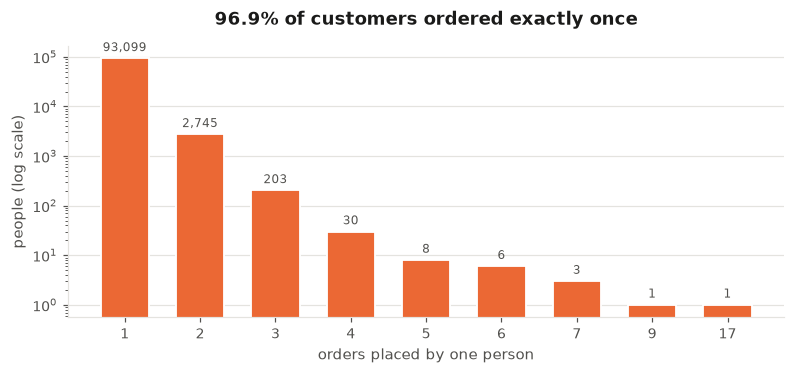

In [25]:
cu = data["customers"].customer_unique_id.value_counts()
dist = cu.value_counts().sort_index()

print(f"distinct people (customer_unique_id) : {cu.size:,}")
print(f"order-level ids (customer_id)        : {data['customers'].customer_id.nunique():,}")
print(f"people with more than one order      : {int((cu > 1).sum()):,}  "
      f"({(cu > 1).mean()*100:.2f}% of people)")
print(f"most orders by a single person        : {cu.max()}")
print()
print("Orders per person:")
for k, v in dist.items():
    print(f"  {k:>2} order(s): {v:>6,} people   {v/cu.size*100:>6.2f}%")

fig, ax = plt.subplots(figsize=(8.4, 3.2))
bars = ax.bar(dist.index.astype(str), dist.values, color=ACCENT,
              width=0.64, edgecolor=SURFACE, linewidth=1.2)
for bar, v in zip(bars, dist.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.4,
            f"{v:,}", ha="center", fontsize=8, color=INK_SOFT)
ax.set_yscale("log")
ax.set_xlabel("orders placed by one person")
ax.set_ylabel("people (log scale)")
ax.set_title("96.9% of customers ordered exactly once")
tidy(ax)
plt.show()

**Only 3.12% of customers ever placed a second order.** This single number
reshapes Module 2, and handling it honestly is what separates a real analysis
from a template:

- **RFM segmentation still works, but the F dimension is nearly degenerate.**
  When 96.9% of people have frequency = 1, scoring frequency into five equal
  buckets is impossible — most customers tie. Phase 5 will score R and M on
  quintiles and treat F as a small ordinal (1, 2, 3+), and will say so.
- **Cohort retention curves will be very flat and very low.** That is the real
  answer, not a broken chart. The useful question becomes *"which cohorts and
  categories retain even slightly better than 3%?"*
- **CLV must be labelled a proxy.** With almost no repeat history there is no
  basis for predicting future value. We report **historical** customer value and
  name it that.

Reporting a 3% repeat rate as a finding — with its consequences for methodology
— is stronger than quietly producing a retention chart that implies otherwise.

### Other observations from this profiling pass

1. **Referential integrity is excellent** — zero orphans in 6 of 7 relationships.
2. **Delivery performance looks good on the surface**: 91.9% of delivered orders
   arrived on or before the estimated date, on average 11 days early. That raises
   a question for Module 5: are the estimates deliberately pessimistic? A
   consistently early delivery against a padded promise is not the same as fast
   delivery.
3. **Revenue is concentrated in `delivered` orders** (97.3% of GMV), so status
   filtering barely moves headline revenue — but the rule still has to be explicit.
4. **The review distribution is J-shaped**, so the 4.09 average hides a hard core
   of 11.5% one-star experiences.
5. **Geography is heavily concentrated** — see the state counts above.
6. **Seller concentration is extreme**: one seller appears in 2,033 order items,
   another product in 527. Module 4 should examine dependence on a few sellers.

## 11 · Data quality issues

Consolidated register. Every item is counted from the data, classified by
severity, and assigned a Phase 3 decision. **Nothing has been fixed in this
notebook** — measuring and fixing are deliberately separate steps.

In [26]:
rv2 = data["reviews"]
dup_rid = rv2.review_id.value_counts()
dup_rid = dup_rid[dup_rid > 1]
delivered = orders[orders.order_status == "delivered"]

issues = [
    ("Q01", "orders", "8 orders have status 'delivered' but no delivery date",
     int((delivered.order_delivered_customer_date.isna()).sum()), "High",
     "Exclude from delivery-time metrics; keep in revenue. Document the 96,470 denominator."),
    ("Q02", "reviews", "review_id is not unique (789 ids reused across orders)",
     int(len(dup_rid)), "High",
     "Do NOT dedupe blindly. Use (review_id, order_id) as PK. For order-level rating use one score per order."),
    ("Q03", "products", "2 categories missing from the translation table (13 products)",
     13, "Medium",
     "LEFT JOIN, then supply 'pc_gamer' and 'portateis_cozinha_e_preparadores_de_alimentos' English names manually."),
    ("Q04", "products", "product_category_name is NULL",
     int(data["products"].product_category_name.isna().sum()), "Medium",
     "Label as 'unknown' rather than dropping — these products still carry real revenue."),
    ("Q05", "orders", "Orders with no line items (cannot contribute revenue)",
     775, "Medium",
     "Keep in the orders table; exclude from AOV denominator. Mostly unavailable/canceled."),
    ("Q06", "orders", "Partial months at both ends of the date range distort trends",
     4, "High",
     "Restrict trend/growth/cohort analysis to 2017-01..2018-08. Totals use all data."),
    ("Q07", "orders", "2016 has only 329 orders, making full-year YoY meaningless",
     329, "High",
     "Report YoY only as 2018 Jan-Aug vs 2017 Jan-Aug."),
    ("Q08", "orders", "Delivered to customer before carrier handoff (impossible sequence)",
     int((orders.order_delivered_customer_date < orders.order_delivered_carrier_date).sum()), "Low",
     "Flag with a data_quality_flag column; do not alter timestamps."),
    ("Q09", "payments", "payment_value = 0",
     int((pays.payment_value == 0).sum()), "Low",
     "Flag and retain; too few to affect totals."),
    ("Q10", "payments", "payment_installments = 0 (not a valid instalment count)",
     int((pays.payment_installments == 0).sum()), "Low",
     "Treat as 1 instalment; document the assumption."),
    ("Q11", "payments", "payment_type = 'not_defined'",
     int((data["payments"].payment_type == "not_defined").sum()), "Low",
     "Map to 'unknown'; retain the rows."),
    ("Q12", "geolocation", "Exact duplicate rows (multiple readings per zip prefix)",
     int(data["geolocation"].duplicated().sum()), "Low",
     "Aggregate to one lat/lng per zip prefix if maps are used. No business metric depends on it."),
    ("Q13", "products", "Missing product dimensions / weight",
     int(data["products"].product_weight_g.isna().sum()), "Low",
     "Leave NULL. Not used by any planned KPI."),
    ("Q14", "orders", "Orders with no review (review coverage is 99.2%)",
     768, "Low",
     "Use a LEFT JOIN for ratings; never INNER, or 768 orders vanish."),
    ("Q15", "orders", "Missing order_approved_at",
     int(data["orders"].order_approved_at.isna().sum()), "Low",
     "Leave NULL; approval lag is not a planned KPI."),
    ("Q16", "products", "Source column names misspelled: product_name_lenght, product_description_lenght",
     2, "Low",
     "Load with original names; rename in cleaned output and document the rename."),
    ("Q17", "reviews", "Review text contains embedded newlines (breaks naive line counting)",
     3852, "Info",
     "Always use a real CSV parser. Relevant again at MySQL import — use proper quoting."),
]

quality = pd.DataFrame(issues, columns=["id", "table", "issue", "count", "severity", "phase_3_decision"])
sev_order = {"High": 0, "Medium": 1, "Low": 2, "Info": 3}
quality = quality.sort_values("severity", key=lambda s: s.map(sev_order)).reset_index(drop=True)
display(quality[["id", "severity", "table", "issue", "count"]])

print("\nSeverity counts:")
print(quality.severity.value_counts().reindex(["High", "Medium", "Low", "Info"]).to_string())
print("\nFull decisions are recorded in documentation/data_quality_report.md.")
print("Reminder: no row has been dropped, filled or altered in this notebook.")

,id,severity,table,issue,count
0,Q01,High,orders,8 orders have status 'delivered' but no delive...,8
1,Q02,High,reviews,review_id is not unique (789 ids reused across...,789
2,Q06,High,orders,Partial months at both ends of the date range ...,4
3,Q07,High,orders,"2016 has only 329 orders, making full-year YoY...",329
4,Q03,Medium,products,2 categories missing from the translation tabl...,13
5,Q04,Medium,products,product_category_name is NULL,610
6,Q05,Medium,orders,Orders with no line items (cannot contribute r...,775
7,Q15,Low,orders,Missing order_approved_at,160
8,Q14,Low,orders,Orders with no review (review coverage is 99.2%),768
9,Q13,Low,products,Missing product dimensions / weight,2



Severity counts:
severity
High      4
Medium    3
Low       9
Info      1

Full decisions are recorded in documentation/data_quality_report.md.
Reminder: no row has been dropped, filled or altered in this notebook.


## 12 · Summary and next steps

### What we established

| Question | Answer |
|---|---|
| Files present | 9 of 9, all readable |
| Total records | 1,551,933 rows across 9 tables |
| Analysis window | 2016-09 → 2018-10; **stable window 2017-01 → 2018-08** |
| Orders | 99,441 (97.0% delivered) |
| Distinct people | 96,096 — only **3.12%** ordered more than once |
| Product revenue (GMV) | 13,591,643.70 BRL (`SUM(order_items.price)`) |
| Referential integrity | Zero orphans in 6 of 7 relationships |
| Primary keys | 2 tables need **composite** keys; `reviews` has no natural single key |
| Mean review score | 4.09, but J-shaped — 11.5% are 1-star |
| On-time delivery | 91.89% of 96,476 orders with a delivery date |
| Data quality issues | 17 logged: 4 High, 3 Medium, 9 Low, 1 Info |

### Decisions made in this phase

1. **Revenue** = `SUM(order_items.price)`, excluding freight, excluding
   canceled/unavailable orders.
2. **Customer counting** uses `customer_unique_id`; joins use `customer_id`.
3. **Trend window** = 2017-01 to 2018-08. YoY = 2018 Jan–Aug vs 2017 Jan–Aug.
4. **RFM** will treat frequency as a small ordinal, not a quintile.
5. **CLV** is reported as historical value, explicitly labelled a proxy.
6. **No row is dropped** without being counted and documented first.

### Phase 1 is complete. Next: Phase 2 — Excel exploration

Phase 2 verifies a handful of these figures **by hand in a spreadsheet**. That
sounds redundant after this notebook, and it is the point: an independent manual
check is how you catch a bug in your own pipeline. If a pivot table disagrees
with pandas, one of them is wrong and it matters which.

Then Phase 3 acts on the 16 issues above and produces the cleaned tables.